PyMC Logistic Regression Demo:



*   Define priors
*   Construct sigmoid
*   Bernoulli likelihood
*   Sampling posterior







In [1]:
import pymc as pm
import numpy as np

x = np.array([1,2,3,5,7])
y = np.array([0,0,0,1,1])

with pm.Model() as logistic_model:

    beta0 = pm.Normal("beta0", mu=0, sigma=10)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)

    logit_p = beta0 + beta1 * x

    p = pm.math.sigmoid(logit_p)

    obs = pm.Bernoulli("obs", p=p, observed=y)

    trace = pm.sample(2000, tune=1000)

Output()

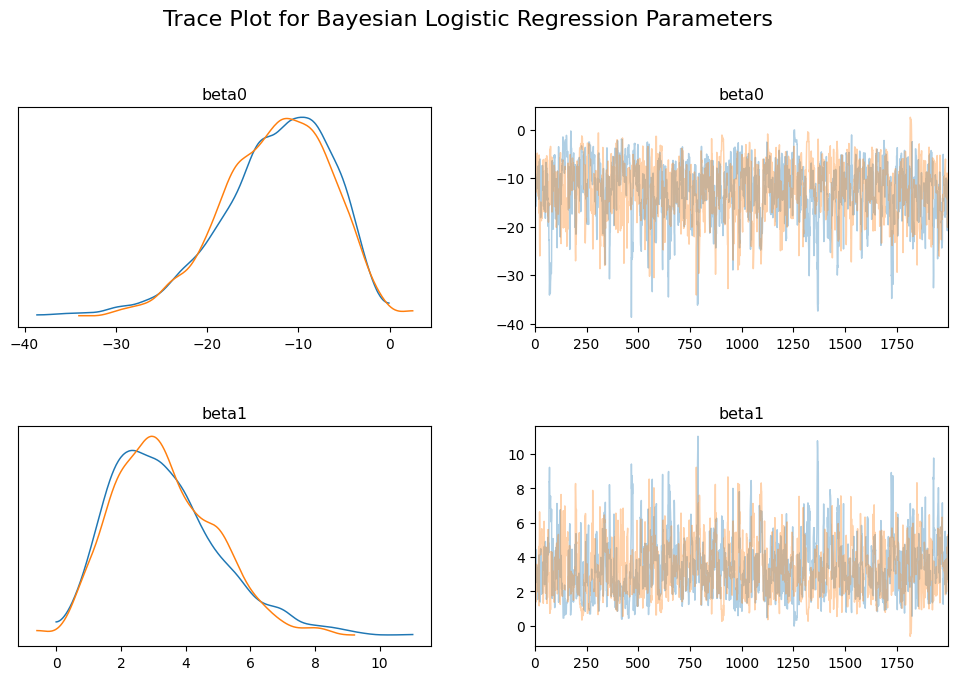

In [3]:
import arviz as az
import matplotlib.pyplot as plt

axes = az.plot_trace(
    trace,
    var_names=["beta0", "beta1"],
    figsize=(12, 7),
    compact=False
)

plt.subplots_adjust(
    hspace=0.45,
    wspace=0.25
)

plt.suptitle(
    "Trace Plot for Bayesian Logistic Regression Parameters",
    fontsize=16,
    y=1.02
)

plt.savefig("bayesian_logistic_traceplot.png", dpi=300, bbox_inches="tight")
plt.show()

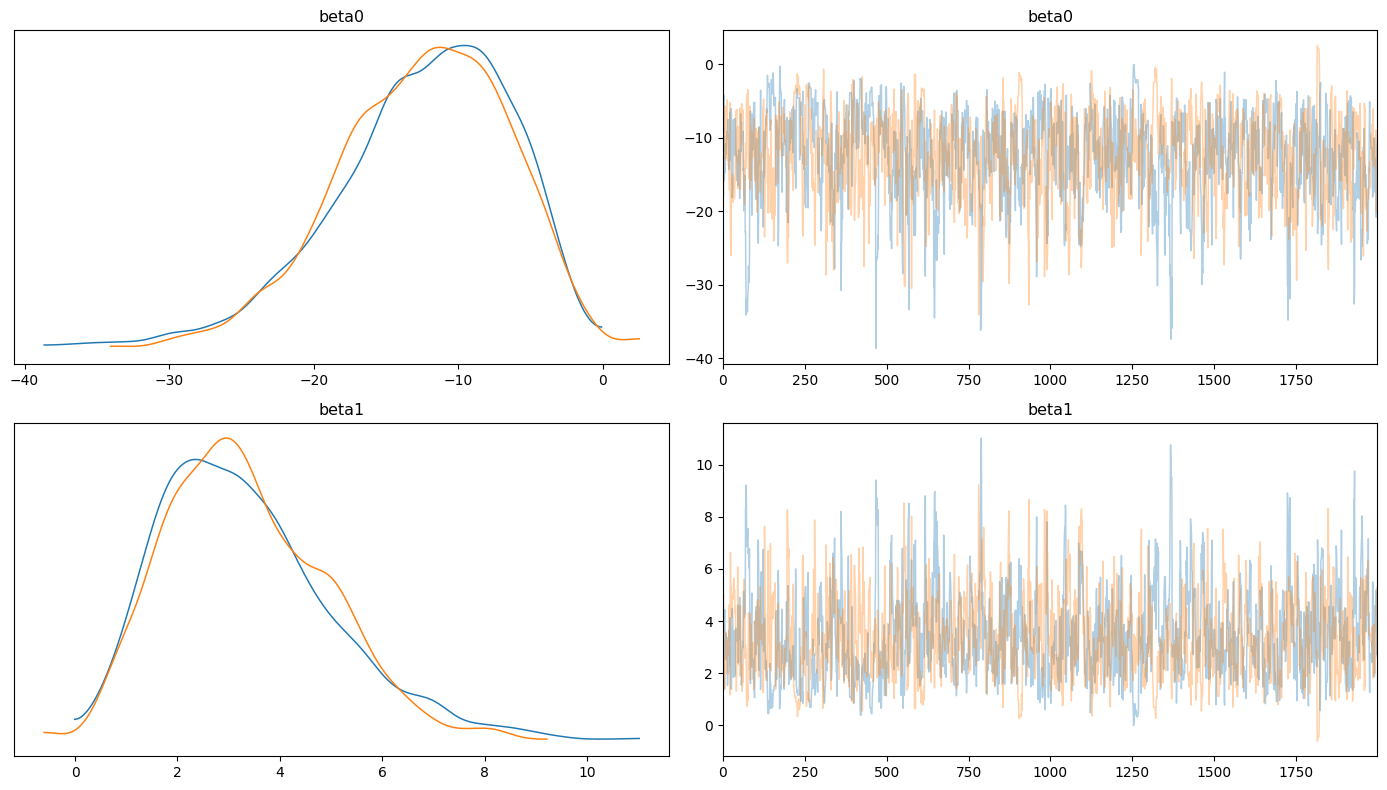

In [4]:
az.plot_trace(
    trace,
    var_names=["beta0", "beta1"],
    figsize=(14, 8),
    compact=False
)

plt.tight_layout()
plt.show()

In [5]:
with logistic_model:
    ppc = pm.sample_posterior_predictive(trace)

Output()

PyMC Poisson Regression

In [6]:
import pymc as pm
import numpy as np

x = np.array([1,2,3,4,5])
y = np.array([2,3,4,7,11])

with pm.Model() as poisson_model:

    beta0 = pm.Normal("beta0", 0, 10)
    beta1 = pm.Normal("beta1", 0, 10)

    mu = pm.math.exp(beta0 + beta1 * x)

    obs = pm.Poisson("obs", mu=mu, observed=y)

    trace = pm.sample(2000, tune=1000)

Output()

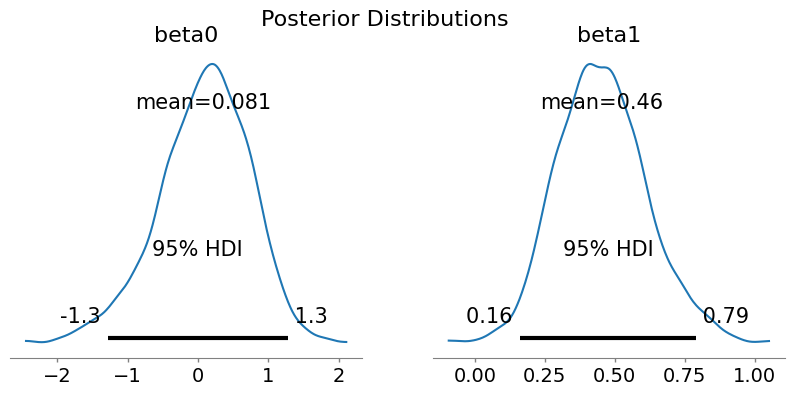

In [7]:
##Posterior Distribution
az.plot_posterior(
    trace,
    var_names=["beta0", "beta1"],
    figsize=(10, 4),
    hdi_prob=0.95
)

plt.suptitle(
    "Posterior Distributions",
    fontsize=16
)

plt.show()